# Walkthrough: Preparing data for METIS

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These tutorials use a CPU and the full original SIRDS bank. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `7a0813987944`](https://github.com/OJWatson/metis/tree/7a081398794492c82d92812b5801900f62f8639a).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Short uv setup cell shared by downloadable notebooks."""

import os
from pathlib import Path
import re
import shlex
import subprocess
import sys


def prepare_colab(revision):
    """Use the checkout's locked environment in Colab's active interpreter."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    if not (os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION")):
        print("Using your local METIS environment.")
        return
    # The source commit matches the results saved in this notebook.
    source = Path("/content/metis-tutorial")
    commands = f'''
set -euo pipefail
export PATH="$HOME/.local/bin:$PATH"
command -v uv >/dev/null || curl -LsSf https://astral.sh/uv/0.7.22/install.sh | sh
[ -d {source}/.git ] || git clone -q https://github.com/OJWatson/metis.git {source}
git -C {source} fetch -q origin {revision}
git -C {source} checkout -q --detach {revision}
uv sync --project {source} --python {shlex.quote(sys.executable)} --locked --inexact --no-dev --extra docs --no-editable
'''
    subprocess.run(
        ["bash", "-c", commands], check=True,
        env={**os.environ, "UV_PROJECT_ENVIRONMENT": sys.prefix, "UV_NO_MODIFY_PATH": "1"},
    )
    print("METIS is ready. If Colab reports a library-version conflict or asks for a restart, restart the session, then Run all.")


prepare_colab("7a081398794492c82d92812b5801900f62f8639a")


Before training a surrogate, you need a dataset of simulator inputs (parameters)
paired with outputs (realisations). We will use the [SIRDS model](https://ojwatson.github.io/metis/basics/sirds-example.html)
to see how these are organised, then load and split the data with METIS.

The package includes the original SIRDS bank: 1,000 parameter settings, five
realisations per setting and 200 days. You can follow the whole walkthrough
without running the simulator yourself. The same loading functions accept data
from your own simulator, whether it was written in Python, R or another language.

## Flattening a single realisation

A simulation table has one row per time point. For example, take the infected
counts from the first SIRDS realisation:

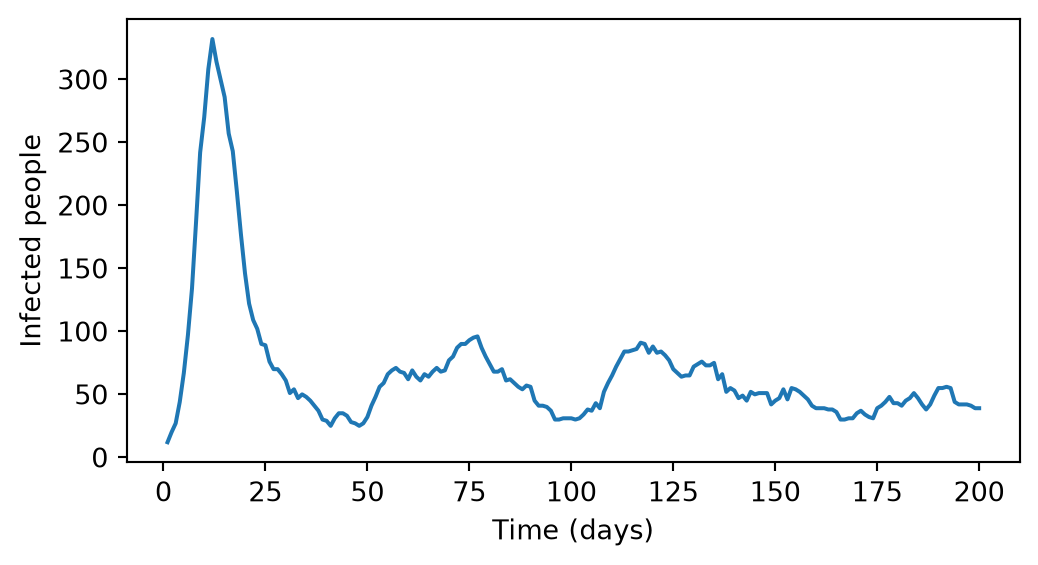

,t,I_t
0,1.0,12.0
1,2.0,20.0
2,3.0,27.0
3,4.0,44.0
4,5.0,67.0


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from metis import SimulationDataset, load_example

example = load_example()
one_run = pd.DataFrame(example.outputs[0], columns=example.output_names)
one_run["t"] = example.times

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(one_run.t, one_run.I_t)
ax.set(xlabel="Time (days)", ylabel="Infected people")
plt.show()
one_run[["t", "I_t"]].head()

This realisation has 200 rows, one for each day. The other compartment counts
can be stored as additional columns on the same rows.

## Multiple SIRDS realisations

We also need to store the simulator inputs and distinguish realisations with
the same inputs. Input parameters become columns repeated along each
trajectory. A `rep` column identifies each realisation at that parameter
setting.

Here we turn the bundled bank's arrays into this long table:

In [2]:
frames = []
for inputs, outputs, rep in zip(
    example.inputs, example.outputs, example.replicate_ids
):
    frame = pd.DataFrame(outputs, columns=example.output_names)
    frame["t"] = example.times
    frame["rep"] = rep
    for name, value in zip(example.input_names, inputs):
        frame[name] = value
    frames.append(frame)

df = pd.concat(frames, ignore_index=True)
df[["I_0", "beta", "gamma", "omega", "mu", "rep", "t", "S_t", "I_t", "R_t", "D_t"]].head()

,I_0,beta,gamma,omega,mu,rep,t,S_t,I_t,R_t,D_t
0,0.010111,0.770961,0.241203,0.027984,0.017867,1,1.0,986.0,12.0,2.0,0.0
1,0.010111,0.770961,0.241203,0.027984,0.017867,1,2.0,974.0,20.0,5.0,1.0
2,0.010111,0.770961,0.241203,0.027984,0.017867,1,3.0,962.0,27.0,10.0,1.0
3,0.010111,0.770961,0.241203,0.027984,0.017867,1,4.0,942.0,44.0,13.0,1.0
4,0.010111,0.770961,0.241203,0.027984,0.017867,1,5.0,910.0,67.0,22.0,1.0


The same `rep` values can be reused at different parameter settings. All five
realisations at one setting share their input values; their outputs differ
because the simulator is stochastic.

## Sampling the parameter space

When building a simulation bank, consider which regions of the parameter space
you need to cover. A simulator may be especially sensitive in some regions,
and parameters may be physically constrained. The SIRDS example samples inputs
uniformly within specified ranges. Latin hypercube sampling is another common
choice for spreading a limited number of simulations across the input space.

The pair plot below shows all 1,000 settings in the original bank. Each panel
shows a pair of input parameters, with their individual distributions on the
diagonal. The same bank is used throughout the training examples.

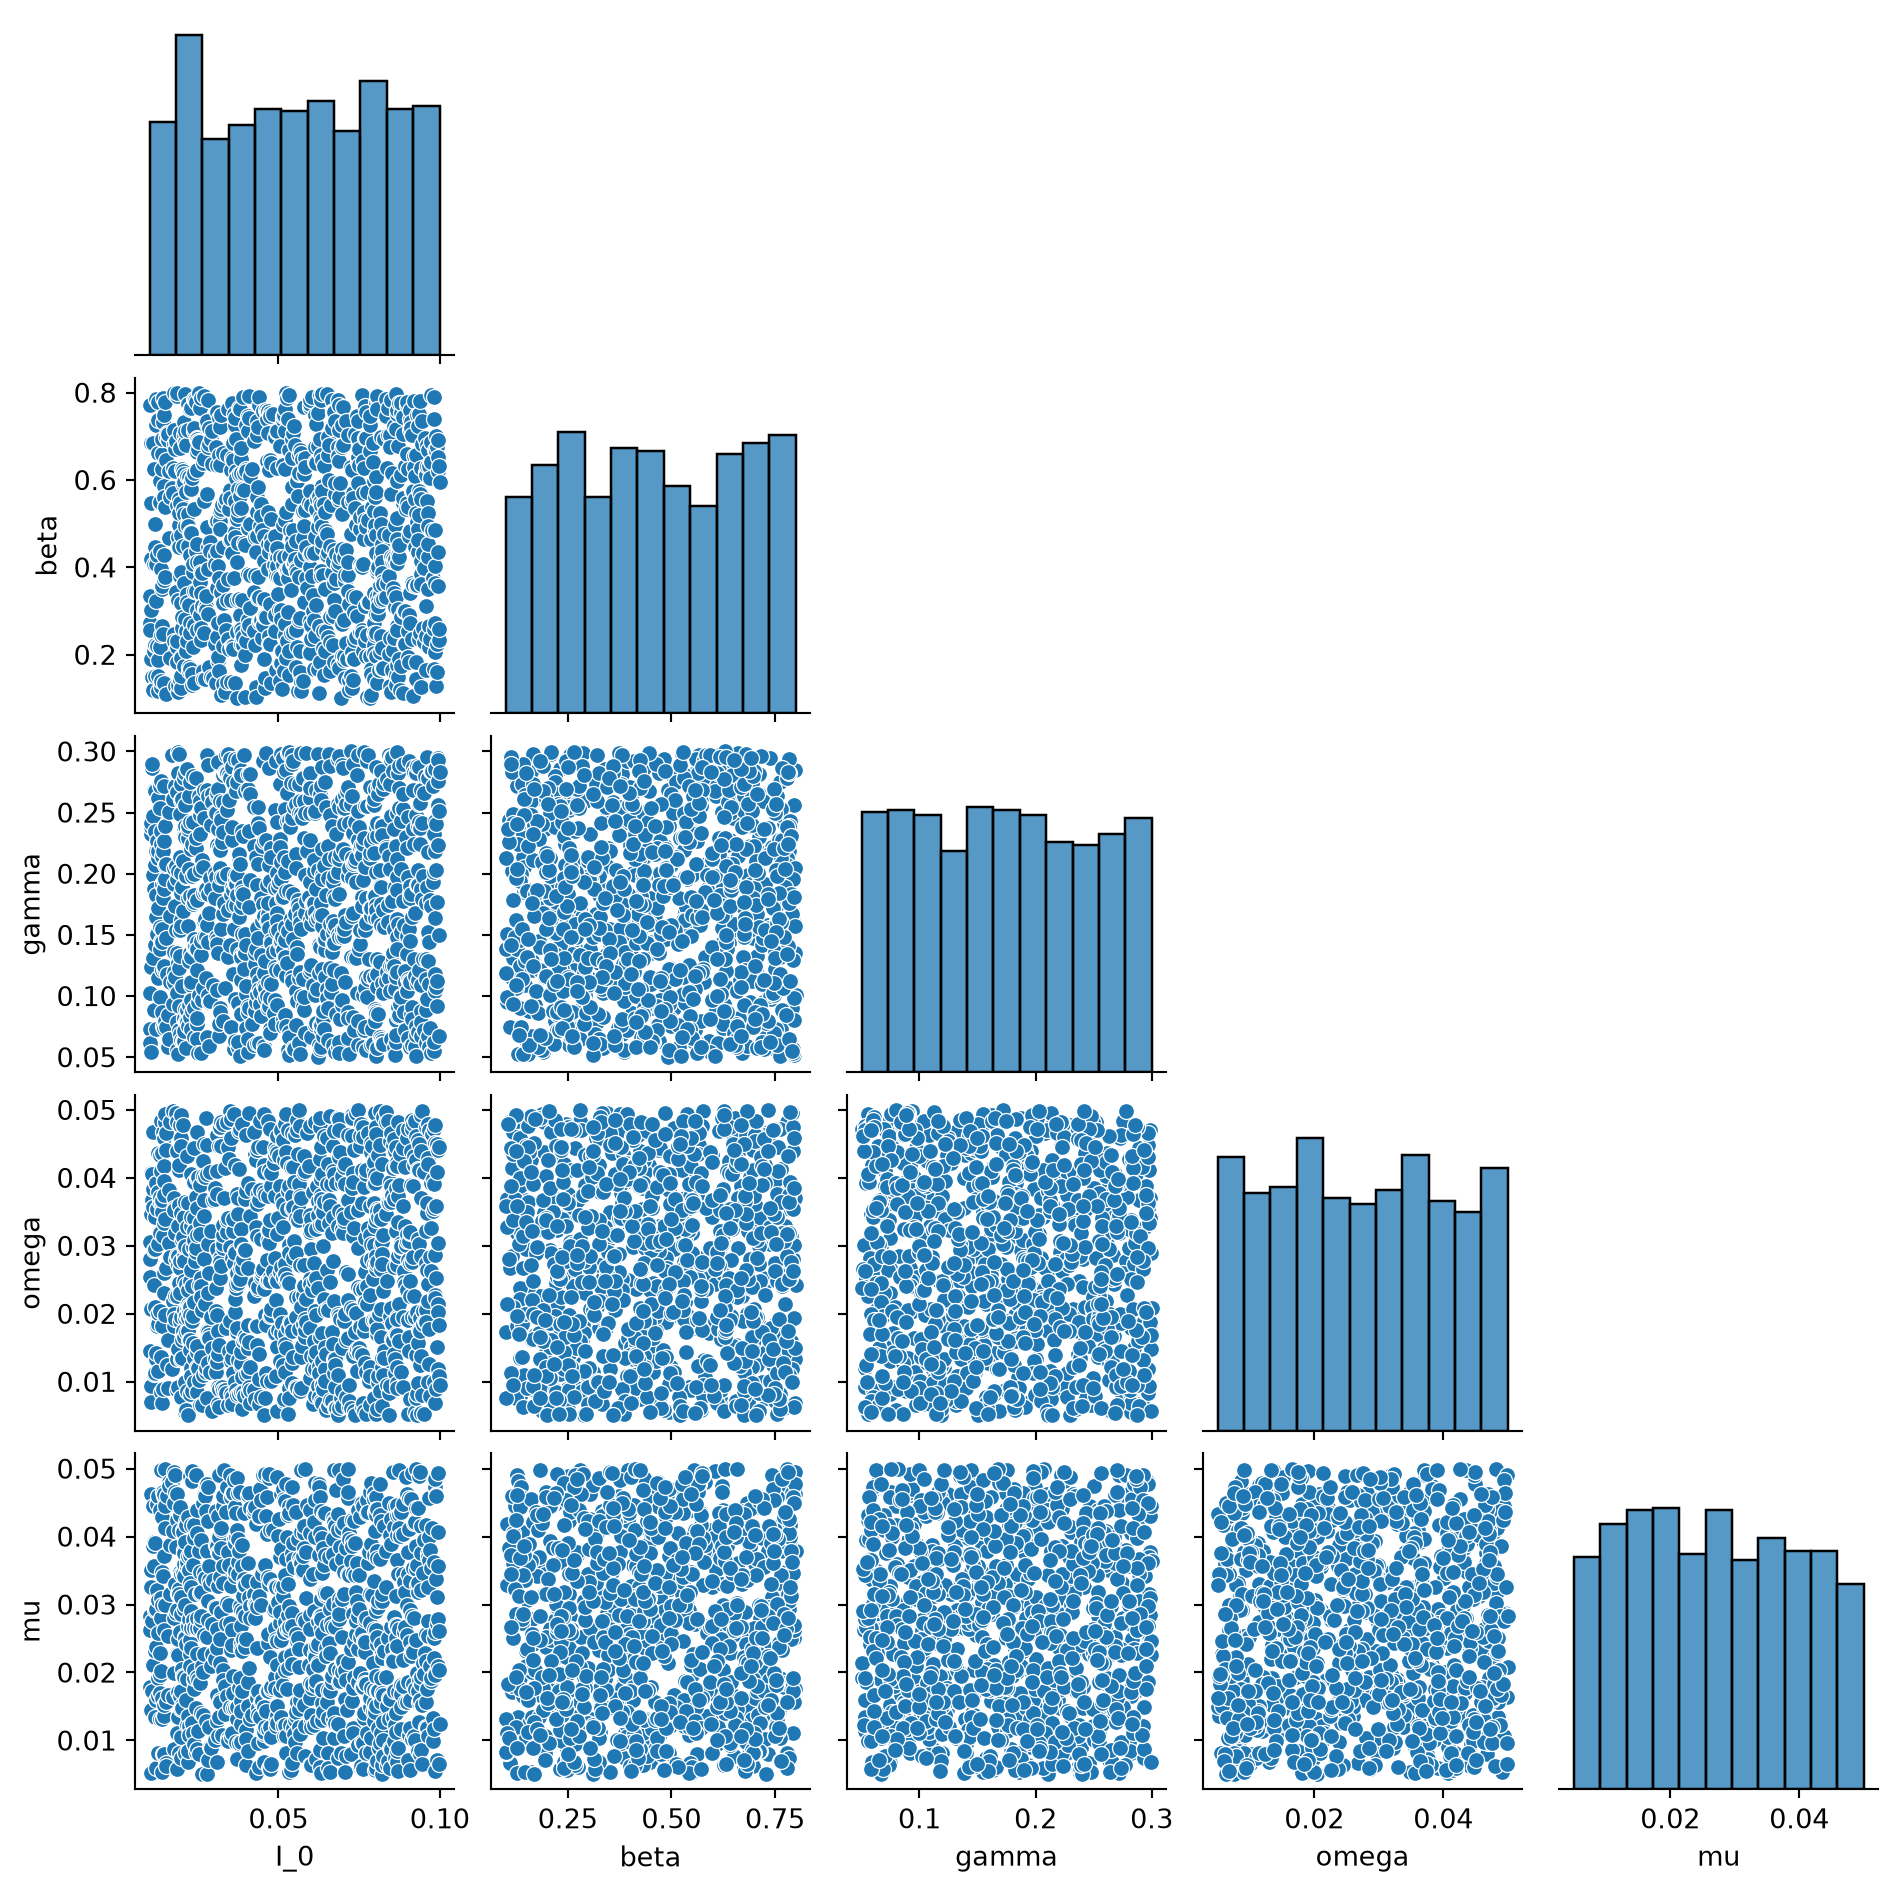

1,000 settings × 5 realisations × 200 days = 1,000,000 rows


In [3]:
#| fig-cap: "Original SIRDS bank: all 1,000 parameter settings, with five stochastic realisations at each setting."
import seaborn as sns

settings = df[list(example.input_names)].drop_duplicates()
sns.pairplot(settings, corner=True, height=2)
plt.show()
print(f"{len(settings):,} settings × 5 realisations × 200 days = {len(df):,} rows")

*Original SIRDS bank: all 1,000 parameter settings, with five stochastic realisations at each setting.*

## Loading the full dataset

Tell METIS which columns contain the inputs and outputs:

In [4]:
input_names = ["I_0", "beta", "gamma", "omega", "mu"]
output_names = ["S_t", "I_t", "R_t", "D_t"]
bank = SimulationDataset.from_frame(df, inputs=input_names, outputs=output_names)
print("Inputs (realisations, parameters):", bank.inputs.shape)
print("Outputs (realisations, time points, compartments):", bank.outputs.shape)

Inputs (realisations, parameters): (5000, 5)
Outputs (realisations, time points, compartments): (5000, 200, 4)


`from_frame` accepts pandas or Polars data frames. It checks that values are
finite, that there are no duplicate observations, and that every realisation
has the same complete time grid. The default time and replicate column names
are `t` and `rep`; use the `time=` and `replicate=` arguments if yours differ.

You can save the table as a Parquet file and load it directly in another session:

In [5]:
df.to_parquet("sirds_data.parquet", index=False)
bank = SimulationDataset.from_parquet(
    "sirds_data.parquet", inputs=input_names, outputs=output_names
)
print(f"Loaded {len(bank)} SIRDS realisations")

Loaded 5000 SIRDS realisations


For your own model, replace `df` or the Parquet path and supply your input and
output column names. Keep each input constant within a realisation, and keep
all realisations on the same time grid.

## Splitting for training and evaluation

We need some simulations to fit the model and others to check it. METIS can
make a reproducible split:

In [6]:
split = bank.split(validation_fraction=0.2, test_fraction=0.2, seed=42)
pd.DataFrame([
    {"Partition": name, "Parameter settings": len(set(part.group_keys)),
     "Realisations": len(part)}
    for name, part in [
        ("Training", split.train), ("Validation", split.validation), ("Test", split.test)
    ]
])

,Partition,Parameter settings,Realisations
0,Training,600,3000
1,Validation,200,1000
2,Test,200,1000


The training set is used to fit the neural network. The validation set helps
choose training settings and the best saved weights. The test set is kept
aside for the final check. All realisations at the same inputs stay together,
so the model must predict at parameter settings it has not seen in training.
Scaling is fitted on the training data automatically when you call `fit`.

Next, [install METIS in your own project](https://ojwatson.github.io/metis/basics/installing_metis.html), then follow
the [Hydra crash course](https://ojwatson.github.io/metis/basics/hydra.html) before training. If you are using Colab,
the notebook setup cell handles installation for you.